# Exploración inicial - NHANES 2013–2014 (UCI 887)


Este notebook documenta la **descarga reproducible del dataset**, una exploración descriptiva inicial de **diabetes reportada (`DIQ010`)**, y los pasos para versionar los datos con **DVC**

**Pregunta del proyecto:** ¿qué patrones en indicadores metabólicos y características de los participantes se relacionan con haber reportado un diagnóstico de diabetes?

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

sns.set_style("darkgrid")

pd.set_option("display.max_columns", 30)

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((x for x in candidates if (x / "requirements-eda.txt").exists() or (x / ".git").exists()), None)
if ROOT is None:
    raise RuntimeError("Abre el notebook desde el repositorio del proyecto en VS Code.")
DATA_PATH = ROOT / "data" / "raw" / "NHANES_age_prediction.csv"
OUT = ROOT / "reports" / "figures"
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
print("Raíz:", ROOT)
print("Archivo de datos:", DATA_PATH)

Raíz: d:\Toño\Educación\Postgrados\Maestria Inteligencia Analítica de Datos\2.2. Des_SA\Proyecto\MIAD-DSA-Metabolic-Health-Explorer
Archivo de datos: d:\Toño\Educación\Postgrados\Maestria Inteligencia Analítica de Datos\2.2. Des_SA\Proyecto\MIAD-DSA-Metabolic-Health-Explorer\data\raw\NHANES_age_prediction.csv


## 1. Carga y validación del dataset

Se consulta el **dataset 887** mediante `ucimlrepo` y se conserva una copia CSV sin modificar. Si el archivo ya existe, se reutiliza para no sobrescribir la versión que controla DVC. La descarga requiere conexión a internet en la primera ejecución.

In [2]:
if not DATA_PATH.exists():
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=887)
    raw = dataset.data.original
    if raw is None or raw.empty:
        raise RuntimeError("No fue posible recuperar los datos originales desde UCI 887")
    raw.to_csv(DATA_PATH, index=False)
    print("Datos descargados desde UCI")
else:
    print("Se utilizará el CSV local existente")

df = pd.read_csv(DATA_PATH)
required = {"SEQN", "age_group", "RIDAGEYR", "RIAGENDR", "PAQ605", "BMXBMI", "LBXGLU", "DIQ010", "LBXGLT", "LBXIN"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Columnas faltantes: {sorted(missing)}")
print(f"Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas")
if len(df) != 6287:
    print("Advertencia: el conteo difiere de las 6.287 observaciones declaradas en UCI; revisar versión")
display(df.head())

Se utilizará el CSV local existente
Dimensiones: 2,278 filas y 10 columnas
Advertencia: el conteo difiere de las 6.287 observaciones declaradas en UCI; revisar versión


,SEQN,age_group,RIDAGEYR,RIAGENDR,PAQ605,BMXBMI,LBXGLU,DIQ010,LBXGLT,LBXIN
0,73564.0,Adult,61.0,2.0,2.0,35.7,110.0,2.0,150.0,14.91
1,73568.0,Adult,26.0,2.0,2.0,20.3,89.0,2.0,80.0,3.85
2,73576.0,Adult,16.0,1.0,2.0,23.2,89.0,2.0,68.0,6.14
3,73577.0,Adult,32.0,1.0,2.0,28.9,104.0,2.0,84.0,16.15
4,73580.0,Adult,38.0,2.0,1.0,35.9,103.0,2.0,81.0,10.92


## 2. Estructura y calidad básica

Aquí verificamos tipos, faltantes y rangos, **sin concluir aún** que los datos estén limpios ni que sean representativos del país sin considerar el diseño muestral.

In [3]:
display(pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum(), "porcentaje_nulos": (df.isna().mean()*100).round(2)}))
display(df[["RIDAGEYR", "BMXBMI", "LBXGLU", "LBXGLT", "LBXIN"]].describe().T.round(2))

,tipo,nulos,porcentaje_nulos
SEQN,float64,0,0.0
age_group,object,0,0.0
RIDAGEYR,float64,0,0.0
RIAGENDR,float64,0,0.0
PAQ605,float64,0,0.0
BMXBMI,float64,0,0.0
LBXGLU,float64,0,0.0
DIQ010,float64,0,0.0
LBXGLT,float64,0,0.0
LBXIN,float64,0,0.0


,count,mean,std,min,25%,50%,75%,max
RIDAGEYR,2278.0,41.80,20.16,12.00,24.00,41.00,58.00,80.00
BMXBMI,2278.0,27.96,7.25,14.50,22.80,26.80,31.20,70.10
LBXGLU,2278.0,99.55,17.89,63.00,91.00,97.00,104.00,405.00
LBXGLT,2278.0,114.98,47.06,40.00,87.00,105.00,130.00,604.00
LBXIN,2278.0,11.83,9.72,0.14,5.86,9.04,14.44,102.29


Una vez determinado que no existen valores nulos en el dataset, pasamos a revisar de forma individual cada una de las variables por valores duplicados y calidad de los datos existentes.

Nuestras hipótesis son:

- `SEQN`: Debería ser 0, de otra forma, revisar los duplicados existentes
- `age_group`: Conteo por categoría, la gran mayoría deberían cubrir valores de "Adult" o "Senior"
- Edad por `age_group`: Valores máximos y mínimo con sentido.

In [4]:
# Duplicados SEQN

display(df['SEQN'].duplicated().sum())

# Validación age_group
display(df["age_group"].value_counts())

# Edad por age_group´
display(df.groupby("age_group")["RIDAGEYR"].agg(["min","max"]))


np.int64(0)

age_group
Adult     1914
Senior     364
Name: count, dtype: int64

,min,max
age_group,,
Adult,12.0,64.0
Senior,65.0,80.0


Sin embargo, tener 0 nulos no significa que no existan códigos adicionales en NHANES como 7 = rechazó ó 9 = no sabe. Debido a esto, revisamos los valores reales de las variables categóricas, los duplicados por cada una de las filas, el tope de edad y los registros con menores de edad.

In [5]:
for col in ["RIAGENDR", "PAQ605", "DIQ010"]:
    print(col)
    display(df[col].value_counts(dropna=False).sort_index())

RIAGENDR


RIAGENDR
1.0    1113
2.0    1165
Name: count, dtype: int64

PAQ605


PAQ605
1.0     409
2.0    1868
7.0       1
Name: count, dtype: int64

DIQ010


DIQ010
1.0      21
2.0    2199
3.0      58
Name: count, dtype: int64

In [6]:
print("Filas duplicadas (columnas):", df.duplicated().sum())

Filas duplicadas (columnas): 0


In [7]:
print("Filas duplicadas por SEQN:", df.drop(columns="SEQN").duplicated().sum())

Filas duplicadas por SEQN: 0


In [8]:
print("Participantes con 80 años:", (df["RIDAGEYR"] == 80).sum())


Participantes con 80 años: 107


In [9]:
menores = df[df["RIDAGEYR"] < 18]
print(f"Participantes menores de edad: {len(menores)} ({len(menores) / len(df) * 100:.1f}%)")
print("Menores con diabetes reportada (Sí):", (menores["DIQ010"] == 1).sum())

Participantes menores de edad: 328 (14.4%)
Menores con diabetes reportada (Sí): 0


Modificamos variables categóricas como enteros


In [10]:
for col in ["SEQN", "RIAGENDR", "PAQ605", "DIQ010"]:
    df[col] = df[col].astype(int)
display(df.dtypes.astype(str).to_frame("tipo"))

,tipo
SEQN,int64
age_group,object
RIDAGEYR,float64
RIAGENDR,int64
PAQ605,int64
BMXBMI,float64
LBXGLU,float64
DIQ010,int64
LBXGLT,float64
LBXIN,float64


## 3. Diabetes reportada: codificación y distribución

`DIQ010` es una respuesta de encuesta acerca de si un profesional de salud ha indicado previamente que la persona tiene diabetes. En la codificación NHANES: **1 = Sí; 2 = No; 3 = Borderline/prediabetes; 7 = Rechazó; 9 = No sabe**. Conservamos el conteo de **todas** las respuestas y utilizamos solo 1 y 2 para la comparación binaria. Validar estos códigos con el [cuestionario oficial de NHANES](https://wwwn.cdc.gov/Nchs/Nhanes/2013-2014/DIQ_H.htm).

,codigo_DI Q010,participantes,respuesta
0,1,21,Sí
1,2,2199,No
2,3,58,Prediabetes / borderline


,participantes,porcentaje
diabetes_reportada,,
No,2199,99.05
Sí,21,0.95


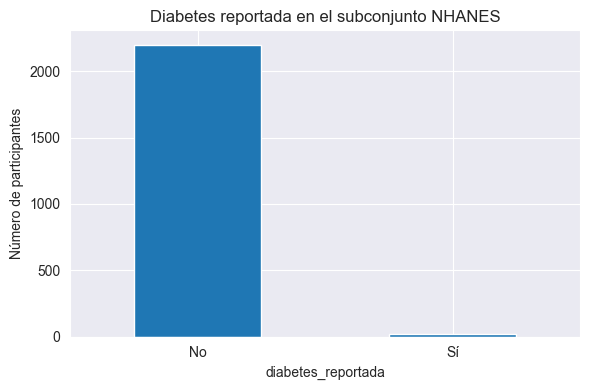

Participantes con Sí/No: 2,220; respuestas excluidas de esta comparación: 58


In [11]:
labels = {1:"Sí", 2:"No", 3:"Prediabetes / borderline", 7:"Rechazó", 9:"No sabe"}
raw_counts = df["DIQ010"].value_counts(dropna=False).sort_index()
all_responses = raw_counts.rename_axis("codigo_DI Q010").reset_index(name="participantes")
all_responses["respuesta"] = all_responses.iloc[:,0].map(labels).fillna("Faltante / otro")
display(all_responses)

valid = df[df["DIQ010"].isin([1,2])].copy()
valid["diabetes_reportada"] = valid["DIQ010"].map({1:"Sí",2:"No"})
counts = valid["diabetes_reportada"].value_counts().reindex(["No","Sí"],fill_value=0)
count_table = pd.DataFrame({"participantes":counts,"porcentaje": (counts/counts.sum()*100).round(2)})
display(count_table)
count_table.to_csv(OUT / "conteo_diabetes.csv", index_label="diabetes_reportada")
ax = counts.plot(kind="bar", rot=0, title="Diabetes reportada en el subconjunto NHANES", ylabel="Número de participantes", figsize=(6,4))
plt.tight_layout()
plt.savefig(OUT / "conteo_diabetes.png", dpi=160)
plt.show()
print(f"Participantes con Sí/No: {len(valid):,}; respuestas excluidas de esta comparación: {len(df)-len(valid):,}")

Teniendo la distinción de la población que reporta y la que no reporta diabetes, nos interesa identificar los rangos de edades para los cuales la población tiende a reportar diabetes.

diabetes_reportada,No,Sí,% Sí
edad_rango,,,
<45,1263,3,0.24
45-64,598,10,1.64
65+,338,8,2.31


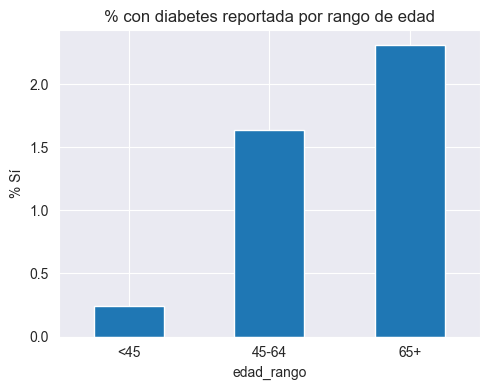

In [12]:
valid["edad_rango"] = pd.cut(valid["RIDAGEYR"], [0, 44, 64, 100],
                             labels=["<45", "45-64", "65+"])

tasa = pd.crosstab(valid["edad_rango"], valid["diabetes_reportada"])
tasa["% Sí"] = (tasa["Sí"] / (tasa["Sí"] + tasa["No"]) * 100).round(2)
display(tasa)

ax = tasa["% Sí"].plot(kind="bar", rot=0, figsize=(5, 4), title="% con diabetes reportada por rango de edad", ylabel="% Sí")
plt.tight_layout()
plt.show()

In [13]:
med = (valid.groupby(["edad_rango", "diabetes_reportada"], observed=True) [["BMXBMI", "LBXGLU", "LBXGLT", "LBXIN"]].median().round(1))
med["n"] = valid.groupby(["edad_rango", "diabetes_reportada"], observed=True).size()
display(med)

BMXBMI  LBXGLU  LBXGLT  LBXIN     n
edad_rango diabetes_reportada                                     
<45        No                    25.8    95.0    97.0    9.3  1263
           Sí                    29.0   160.0   288.0    8.4     3
45-64      No                    27.6   100.0   112.5    8.7   598
           Sí                    29.3   123.0   240.0   11.1    10
65+        No                    27.1   101.0   128.5    8.5   338
           Sí                    28.9   106.5   175.5    7.1     8

Una vez identificada la distribución de los participantes del estudios y sus edades, generamos los histogramas para validar las distribuciones de cada una de las variables

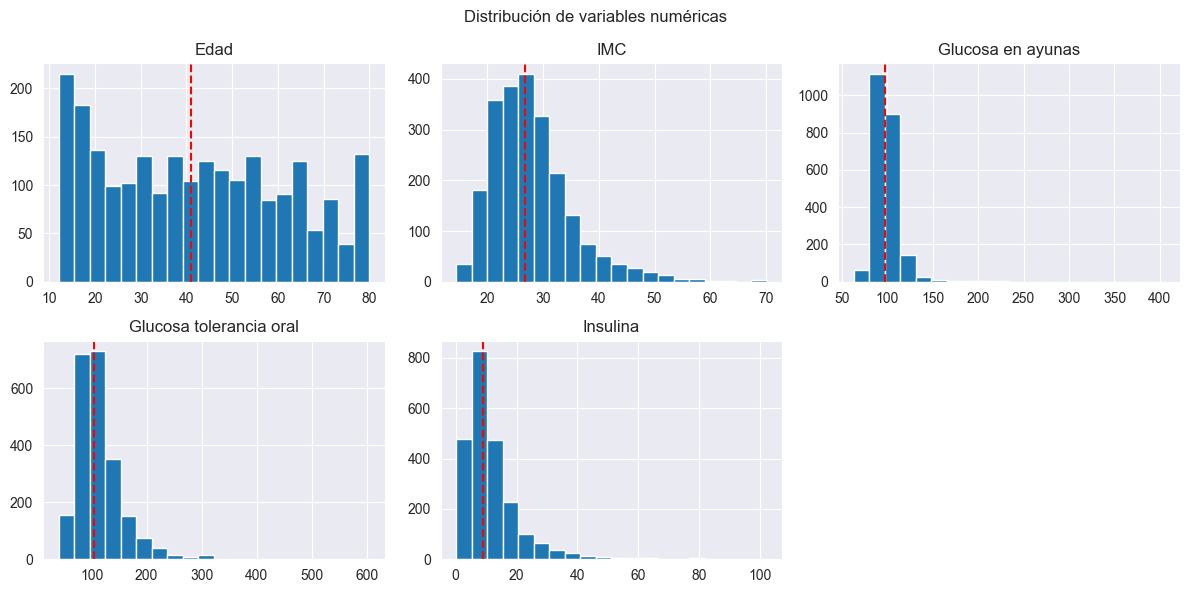

In [14]:
num = ["RIDAGEYR", "BMXBMI", "LBXGLU", "LBXGLT", "LBXIN"]
nombres = {"RIDAGEYR":"Edad", "BMXBMI":"IMC", "LBXGLU":"Glucosa en ayunas", "LBXGLT":"Glucosa tolerancia oral", "LBXIN":"Insulina"}

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, var in zip(axes.flat, num):
    ax.hist(df[var], bins=20, edgecolor="white")
    ax.axvline(df[var].median(), color="red", linestyle="--") # Linea de identificación de la mediana
    ax.set_title(nombres[var])
axes.flat[-1].axis("off")
fig.suptitle("Distribución de variables numéricas")
plt.tight_layout()
plt.show()

In [15]:
resumen = df[num].agg(["median","mean","skew"]).T.round(2)
resumen.columns = ["mediana","media","asimetria"]
display(resumen)

,mediana,media,asimetria
RIDAGEYR,41.00,41.80,0.24
BMXBMI,26.80,27.96,1.33
LBXGLU,97.00,99.55,7.19
LBXGLT,105.00,114.98,2.87
LBXIN,9.04,11.83,2.78


Basados en la información expuesta por los histogramas, podemos inferir que:

- En cuanto a la edad, existe una forma casi simétrica en la población, la población está separada entre 2 categorías de edad con un total de 1914 registros correspondientes a `Adulto` y un total de 364 registrados como `Senior`, también recalcamos que:
    - Adulto: 12 a 64 años -> Consideramos que incluir las edades de 12 a 17 años puede ser un error en esta categoría, sugerimos revisar a fondo qué regla de necogio genera esta inclusión/distinción para poblacion menor de edad.
    - Senior: edad > 65 años.
- Respecto al Indice de masa corporal, existe una asimetría marcada con cola hacia la derecha
- De la población total, un 2.3% de los casos corresponden a adultos de +65 años que tienen diabetes, un 1.6% se encuentra entre 45 y 64 años, y 0.2% tienen menos de 45 años. 
- Observamos que la edad explica una parte del patrón de los datos, entre la población que no cuenta con diabetes, la glucosa tiende a subir con la edad.
- Los resultados de glucosa que presenta la población con diabetes son significativamente más altos
- Por otro lado, la insulina no tiende a variar con el factor edad.

También podemos concluir que:

- Existe un desbalance extremo en la fuente de datos, lo cual representa un riesgo de sesgo para los posibles modelos supervisados a plantear para este ejercicio. Esto también nos llevará a ser más cautelosos al momento de leer e interpretar cualquiera de los registros que dieron "Sí" o positivos para la detección de Diabetes.

También procedemos a revisar los Outliers haciendo uso del rango intercuartil y las posibles distribuciones transformadas.

Vamos a considerar valores extremos todos aquellos valores que están fuera de 1.5 x IQR, este valor servirá como referencia.

Aquellos valores que estén fuera del rango establecido no se eliminarán, es el caso de glucosa e insulina donde estos valores atípicos es posible que representen casos clínicos reales y eliminarlos sería un error.

In [16]:
filas = []
for var in num:
    q1, q3 = df[var].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[var] < lim_inf) | (df[var] > lim_sup)).sum()
    filas.append({"variable": nombres[var], "mínimo": df[var].min(), "máximo": df[var].max(),
                  "límite_inf": round(lim_inf, 1), "límite_sup": round(lim_sup, 1),
                  "n_outliers": n_out, "% outliers": round(n_out / len(df) * 100, 1)})
display(pd.DataFrame(filas).set_index("variable"))

,mínimo,máximo,límite_inf,límite_sup,n_outliers,% outliers
variable,,,,,,
Edad,12.00,80.00,-27.0,109.0,0,0.0
IMC,14.50,70.10,10.2,43.8,88,3.9
Glucosa en ayunas,63.00,405.00,71.5,123.5,104,4.6
Glucosa tolerancia oral,40.00,604.00,22.5,194.5,121,5.3
Insulina,0.14,102.29,-7.0,27.3,150,6.6


Para tener una mejor visual, transformaremos los daotos a una escala log(1 + x) para aquellas variables con una distribución asimétrica. Esto nos ayudará a definir si necesitaremos transformaciones posteriores en la fase de modelado.

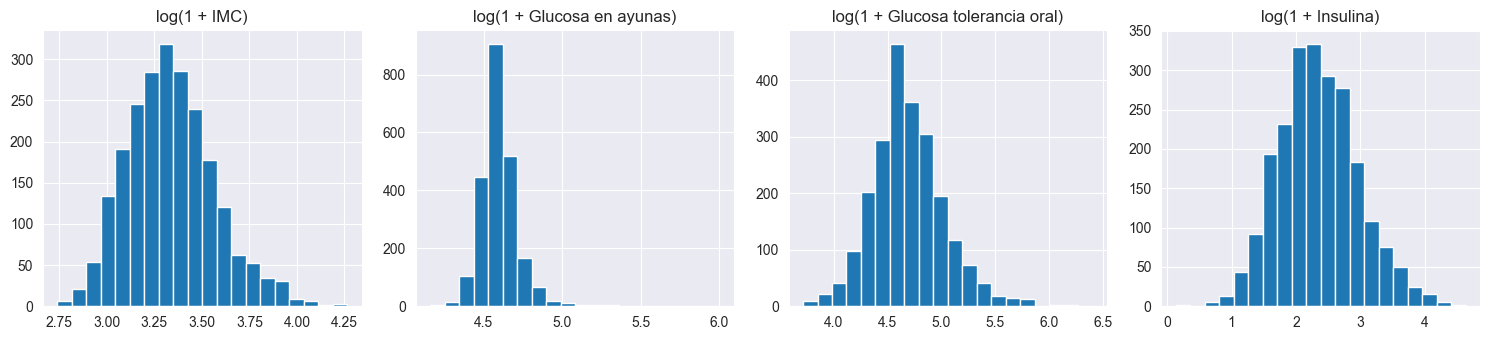

Asimetría después de log(1 + x):


,asimetria
BMXBMI,0.50
LBXGLU,2.76
LBXGLT,0.62
LBXIN,0.31


In [17]:
import numpy as np

vars_log = ["BMXBMI", "LBXGLU", "LBXGLT", "LBXIN"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, var in zip(axes, vars_log):
    ax.hist(np.log1p(df[var]), bins=20, edgecolor="white")
    ax.set_title(f"log(1 + {nombres[var]})")
plt.tight_layout()
plt.savefig(OUT / "histogramas_log.png", dpi=160)
plt.show()

print("Asimetría después de log(1 + x):")
display(np.log1p(df[vars_log]).skew().round(2).to_frame("asimetria"))

## 4. Comparación preliminar de indicadores metabólicos

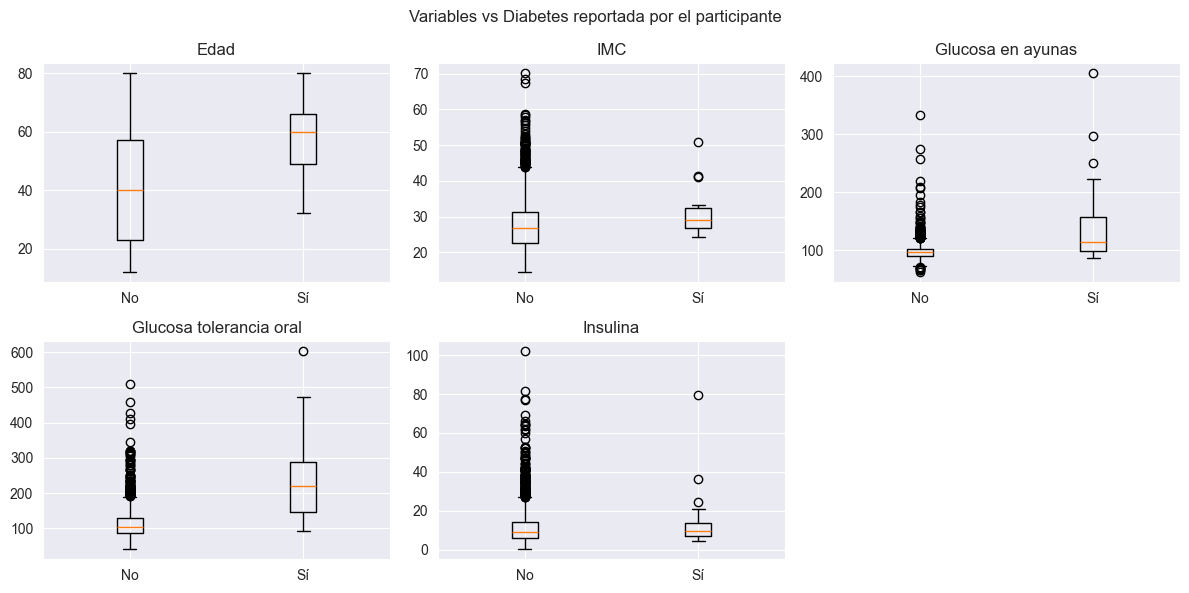

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, v in zip(axes.flat, num):
    grupos = [valid.loc[valid.diabetes_reportada == g, v] for g in ["No", "Sí"]]
    ax.boxplot(grupos, tick_labels=["No", "Sí"])
    ax.set_title(nombres[v])
axes.flat[-1].axis("off")
fig.suptitle("Variables vs Diabetes reportada por el participante")
plt.tight_layout()
plt.savefig(OUT / "boxplots_todas_por_diabetes.png", dpi=160)
plt.show()

Acorde a los boxplot por cada una de las métricas reportadas por los participantes de la encuesta tenemos:

- Es evidente que las personas que reportaron diabetes son mayores que las que no reportaron diabetes
- De igual manera, personas con edades más avanzadas reportaron glucosa en ayudas mucho más alta presentando algunos outliers, sin embargo debemos tener presente que el desbalanceo de clases podrá generar sesgos en los modelos a plantear.

Dado que solo tenemos 21 casos con Diabetes reportada "Sí", decidimos incluir los 58 valores "borderline". 

In [19]:
grupos = df[df["DIQ010"].isin([1, 2, 3])].copy()
grupos["grupo"] = grupos["DIQ010"].map({1: "Sí", 2: "No", 3: "Borderline"})
orden_g = ["No", "Borderline", "Sí"]

filas = []
for var in num:
    for g in orden_g:
        sub = grupos.loc[grupos["grupo"] == g, var]
        filas.append({"variable": nombres[var], "grupo": g, "n": len(sub),
                      "Q1": sub.quantile(0.25), "mediana": sub.median(), "Q3": sub.quantile(0.75)})
tabla_grupos = pd.DataFrame(filas).set_index(["variable", "grupo"]).round(1)
display(tabla_grupos)
tabla_grupos.to_csv(OUT / "resumen_por_grupo_diabetes.csv")

n     Q1  mediana     Q3
variable                grupo                                  
Edad                    No          2199   23.0     40.0   57.0
                        Borderline    58   43.2     60.0   67.0
                        Sí            21   49.0     60.0   66.0
IMC                     No          2199   22.7     26.7   31.2
                        Borderline    58   26.2     30.4   33.0
                        Sí            21   26.9     29.1   32.4
Glucosa en ayunas       No          2199   91.0     97.0  103.0
                        Borderline    58  101.2    112.0  121.0
                        Sí            21   99.0    114.0  158.0
Glucosa tolerancia oral No          2199   86.0    104.0  128.0
                        Borderline    58  110.0    146.5  196.5
                        Sí            21  145.0    219.0  288.0
Insulina                No          2199    5.8      9.0   14.3
                        Borderline    58    8.4     13.3   21.3
                        Sí            21    6.9      9.6   13.6

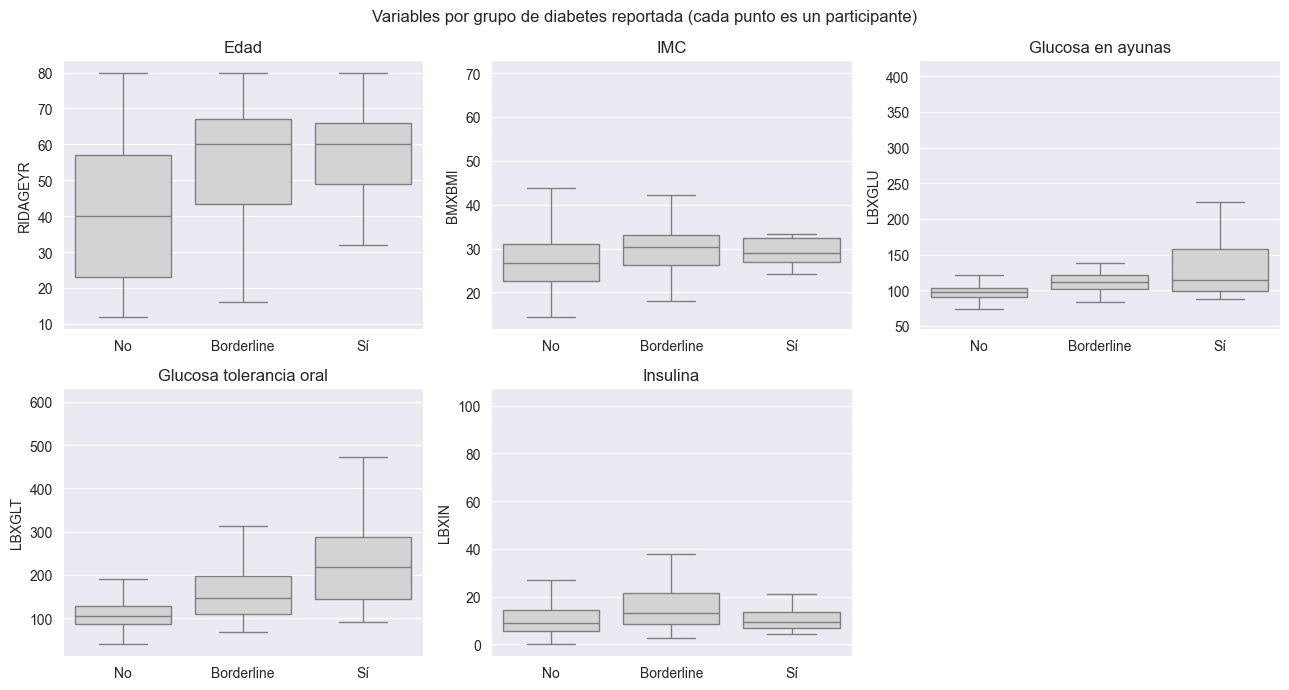

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, var in zip(axes.flat, num):
    sns.boxplot(data=grupos, x="grupo", y=var, order=orden_g, color="lightgray", fliersize=0, ax=ax)
    ax.set_title(nombres[var])
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Variables por grupo de diabetes reportada (cada punto es un participante)")
plt.tight_layout()
plt.savefig(OUT / "puntos_por_grupo_diabetes.png", dpi=160)
plt.show()

## 5. Qué categorías de glucosa tenemos? 

La idea detrás de esta pregunta es identificar cuantas personas con altos niveles de glucosa en ayunas no reportan un diagnostico positivo de diabetes, así como aquellos que tienen glucosa normal.

In [21]:
valid["glu_cat"] = pd.cut(valid["LBXGLU"], [0, 99.9, 125.9, 1000],
                          labels=["<100", "100-125", "≥126"])

conteo = pd.crosstab(valid["glu_cat"], valid["diabetes_reportada"], margins=True)
display(conteo)

pct_fila = (pd.crosstab(valid["glu_cat"], valid["diabetes_reportada"], normalize="index")
              .mul(100).round(2))
display(pct_fila)

diabetes_reportada,No,Sí,All
glu_cat,,,
<100,1361,6,1367
100-125,769,7,776
≥126,69,8,77
All,2199,21,2220


diabetes_reportada,No,Sí
glu_cat,,
<100,99.56,0.44
100-125,99.10,0.90
≥126,89.61,10.39


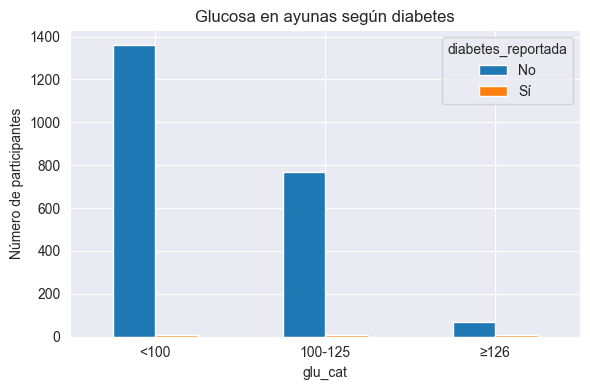

In [22]:
ax = pd.crosstab(valid["glu_cat"], valid["diabetes_reportada"]).plot(
    kind="bar", rot=0, figsize=(6, 4),
    title="Glucosa en ayunas según diabetes",
    ylabel="Número de participantes")
plt.tight_layout()
plt.show()

- El 10.4% de los casos con diabetes superior a 126 corresponden a casos de diabetes reportada.
- Tenemos un total de 69 casos de reportes negativos que cuentan con una Glucosa en ayunas superior a 126.
- Un 29% (6/21) de casos reportados como Diabetes positiva corresponden a registros con Glucosa por debajo de 100, 62% (13/21) están por debajo de 126 y finalmente el 38% de los casos reoportan niveles altos de glucosa.

Es dificil diferenciar los casos de reportes con Diabetes positiva usando únicamente la Glucosa en ayunas dado que existe un mix en cada uno de los rangos determinados para los niveles de glucosa en ayunas.

Entrando más a detalle, consultamos y agregamos categorías de referencia:

- **IMC** (OMS): <18.5 bajo peso, 18.5 -24,9 normal, 25 -29.9 sobrepeso, >30 obesidad.
- **Glucosa a 2 h en la prueba de tolerancia oral** (`LBXGLT`): <140 normal, 140–199 prediabetes, ≥200 rango de diabetes.
- **HOMA-IR** = glucosa en ayunas × insulina. Nos ayudará a resumir la resistencia a la insulina.


In [23]:
valid["imc_cat"] = pd.cut(valid["BMXBMI"], [0, 18.5, 25, 30, 100], right=False,
                          labels=["Bajo peso", "Normal", "Sobrepeso", "Obesidad"])
valid["ogtt_cat"] = pd.cut(valid["LBXGLT"], [0, 140, 200, 1000], right=False,
                           labels=["<140", "140-199", "≥200"])
valid["homa_ir"] = valid["LBXGLU"] * valid["LBXIN"] / 405

for var in ["imc_cat", "ogtt_cat"]:
    tabla = pd.crosstab(valid[var], valid["diabetes_reportada"], margins=True)
    tabla["% Sí"] = (tabla["Sí"] / tabla["All"] * 100).round(2)
    display(tabla)

print("HOMA-IR por diabetes reportada:")
display(valid.groupby("diabetes_reportada")["homa_ir"].describe().round(2))

diabetes_reportada,No,Sí,All,% Sí
imc_cat,,,,
Bajo peso,81,0,81,0.00
Normal,777,1,778,0.13
Sobrepeso,663,11,674,1.63
Obesidad,678,9,687,1.31
All,2199,21,2220,0.95


diabetes_reportada,No,Sí,All,% Sí
ogtt_cat,,,,
<140,1809,5,1814,0.28
140-199,307,5,312,1.60
≥200,83,11,94,11.70
All,2199,21,2220,0.95


HOMA-IR por diabetes reportada:


,count,mean,std,min,25%,50%,75%,max
diabetes_reportada,,,,,,,,
No,2199.0,2.92,2.60,0.03,1.34,2.17,3.51,29.58
Sí,21.0,5.34,6.58,1.09,1.84,3.00,5.27,31.51


La glucosa en ayunas vs la glucosa en tolerancia oral

Mapeamos los casos de marcadores de glucosa en ayunas vs los marcadores de glucosa de tolerancia oral, estos los colocamos en un plano para identificar las coordenadas y los casos que reportaron diabetes vs los que no, teniendo una referencia espacial. Es posible que los casos de no reporte sea por falta de un diagnóstico positivo?

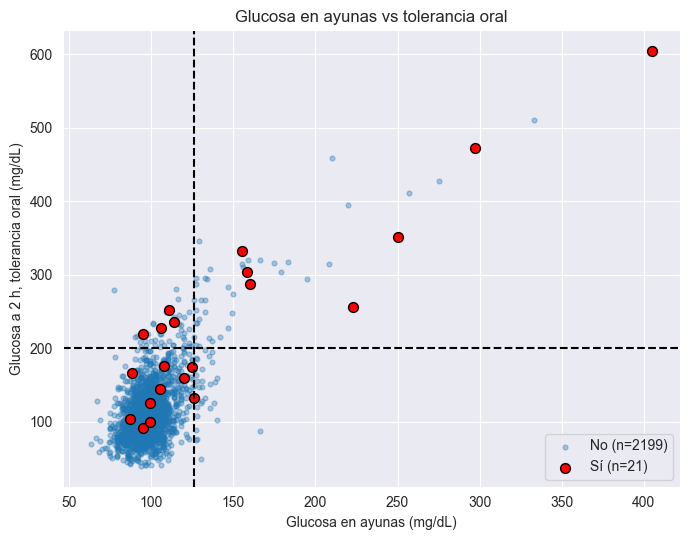

In [24]:
no = valid[valid["diabetes_reportada"] == "No"]
si = valid[valid["diabetes_reportada"] == "Sí"]

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(no["LBXGLU"], no["LBXGLT"], s=12, alpha=0.35, label=f"No (n={len(no)})")
ax.scatter(si["LBXGLU"], si["LBXGLT"], s=50, color="red", edgecolor="black", label=f"Sí (n={len(si)})")
ax.axvline(126, color="black", linestyle="--")
ax.axhline(200, color="black", linestyle="--")
ax.set_xlabel("Glucosa en ayunas (mg/dL)")
ax.set_ylabel("Glucosa a 2 h, tolerancia oral (mg/dL)")
ax.set_title("Glucosa en ayunas vs tolerancia oral")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "dispersion_glucosa_ayunas_vs_ogtt.png", dpi=160)
plt.show()

## 6. Correlaciones entre las variables del dataset

Lo que buscamos ahora tras entender a grandes rasgos la información proporcionada por el negocio, pasamos a 

,Edad,IMC,Glucosa en ayunas,Glucosa tolerancia oral,Insulina,Sexo (mujer=1),Act. vigorosa (Sí=1),Diabetes (Sí=1)
Edad,1.00,0.23,0.31,0.32,-0.11,0.02,-0.01,0.09
IMC,0.23,1.00,0.27,0.22,0.54,0.02,0.05,0.06
Glucosa en ayunas,0.31,0.27,1.00,0.40,0.33,-0.21,0.06,0.09
Glucosa tolerancia oral,0.32,0.22,0.40,1.00,0.24,0.05,-0.06,0.12
Insulina,-0.11,0.54,0.33,0.24,1.00,0.02,-0.04,0.02
Sexo (mujer=1),0.02,0.02,-0.21,0.05,0.02,1.00,-0.16,0.02
Act. vigorosa (Sí=1),-0.01,0.05,0.06,-0.06,-0.04,-0.16,1.00,0.03
Diabetes (Sí=1),0.09,0.06,0.09,0.12,0.02,0.02,0.03,1.00


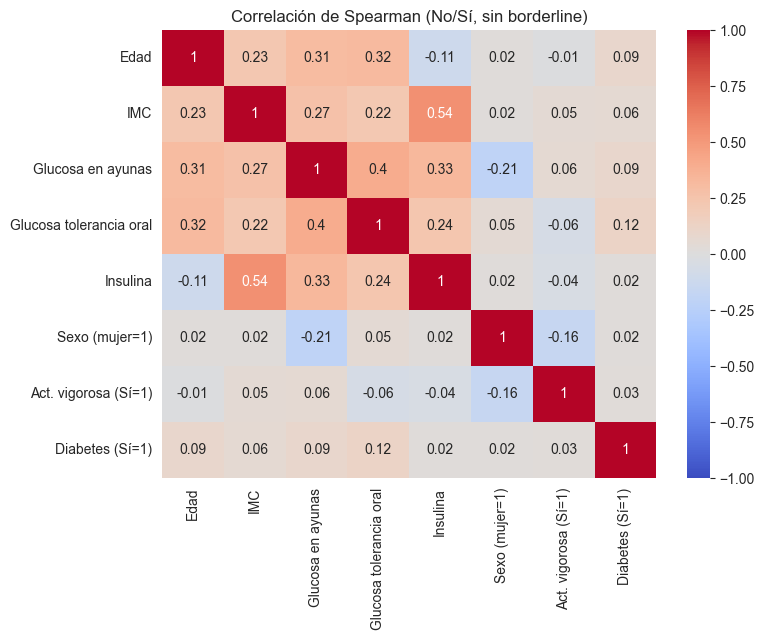

In [25]:
d = valid.copy()
d["Diabetes (Sí=1)"] = (d["DIQ010"] == 1).astype(int)
d["Sexo (mujer=1)"] = (d["RIAGENDR"] == 2).astype(int)
d["Act. vigorosa (Sí=1)"] = d["PAQ605"].map({1: 1, 2: 0})   # otros códigos quedan como NaN

cols = {**nombres, "Diabetes (Sí=1)": "Diabetes (Sí=1)",
        "Sexo (mujer=1)": "Sexo (mujer=1)", "Act. vigorosa (Sí=1)": "Act. vigorosa (Sí=1)"}
orden = list(nombres.values()) + ["Sexo (mujer=1)", "Act. vigorosa (Sí=1)", "Diabetes (Sí=1)"]

corr = d.rename(columns=nombres)[orden].corr(method="spearman").round(2)
display(corr)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman (No/Sí, sin borderline)")
plt.tight_layout()
plt.savefig(OUT / "correlacion_spearman_completa.png", dpi=160)
plt.show()

Existe una correlacion moderada entre IMC y los niveles de insulina, con un spearman de 0.54 podemos determinar que el nivel de insulina puede llegar a acompañarse por el peso de la persona.

La glucosa en ayunas y la tolerancia oral a esta tiene una correlacion moderada de 0.4; es posible que tengamos información valiosa aqui sin que sea redundante

Edad confirma tener una correlación moderada de 0.32 para ambos niveles de Glucosa, esto lo encontramos en pasos previos del estudio; por medio de este análisis lo confirmamos.

Las variables de Glucosa en ayunas y actividad física vigorosa no tienen correlación significativa con la variable género.

Por último, ninguna de las variables cuenta con un índice de correlación de Spearman superior a 0.12, esto nos indica que a simple vista en los datos, y solamente buscando relaciones lineales en estos, ninguna variable podría ser una fuerte candidata para generar diabetes en un paciente.

Sin embargo no estamos considerando relaciones no lineales en este estudio, estas se dejarán para más adelante cuando lleguemos a la etapa de selección del algorítmo de aprendizaje supervisado para el presente estudio.

In [26]:
d = valid.copy()
d["Sexo"] = d["RIAGENDR"].map({1: "Hombre", 2: "Mujer"})
d["Act. vigorosa"] = d["PAQ605"].map({1: "Sí", 2: "No"})   # otros códigos quedan como NaN

for var in ["Sexo", "Act. vigorosa"]:
    conteo = pd.crosstab(d[var], d["diabetes_reportada"], margins=True)
    conteo["% Sí"] = (conteo["Sí"] / conteo["All"] * 100).round(2)
    print(var)
    display(conteo)
    conteo.to_csv(OUT / f"{var.replace('. ', '_').lower()}_por_diabetes.csv")

Sexo


diabetes_reportada,No,Sí,All,% Sí
Sexo,,,,
Hombre,1072,8,1080,0.74
Mujer,1127,13,1140,1.14
All,2199,21,2220,0.95


Act. vigorosa


diabetes_reportada,No,Sí,All,% Sí
Act. vigorosa,,,,
No,1808,15,1823,0.82
Sí,390,6,396,1.52
All,2198,21,2219,0.95


Indicadores por sexo y rango de edad

Es posible revisar la correlación entre el género de la persona y la glucosa en ayunas, es por esto que pasamos a graficar por medio de un Boxplot las diferencias.

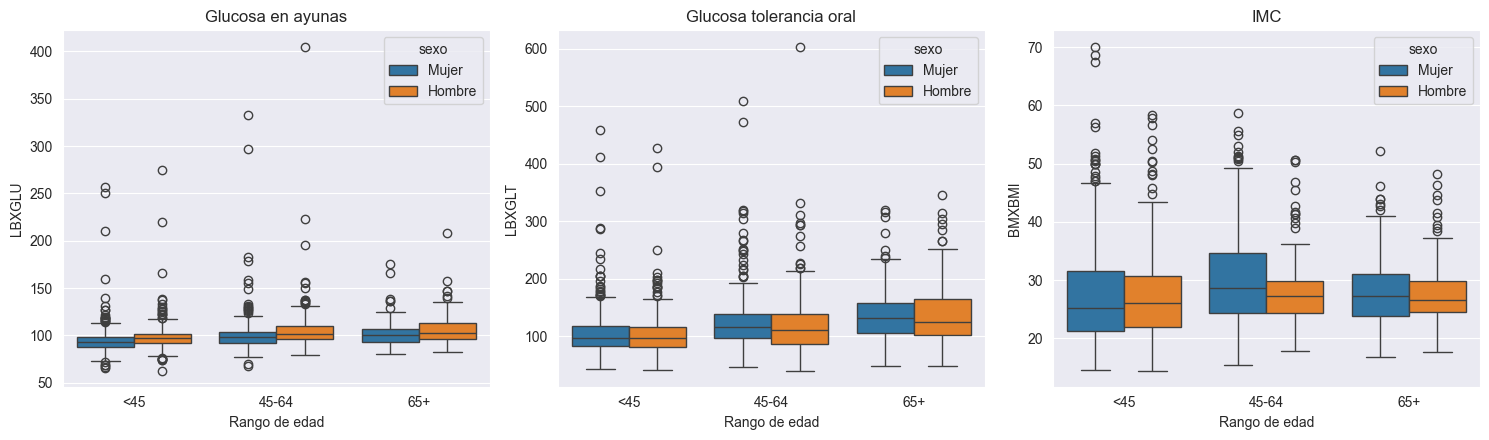

In [ ]:
d = df[df["DIQ010"].isin([1, 2])].copy()
d["edad_rango"] = pd.cut(d["RIDAGEYR"], [0, 44, 64, 100], labels=["<45", "45-64", "65+"])
d["sexo"] = d["RIAGENDR"].map({1: "Hombre", 2: "Mujer"})
nombres = {"LBXGLU": "Glucosa en ayunas", "LBXGLT": "Glucosa tolerancia oral", "BMXBMI": "IMC"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, var in zip(axes, nombres):
    sns.boxplot(data=d, x="edad_rango", y=var, hue="sexo", ax=ax)
    ax.set_title(nombres[var])
    ax.set_xlabel("Rango de edad")
plt.tight_layout()
plt.show()

## 7. Hallazgos

**Datos y calidad**
- El dataset realmente carga 2.278 registros y 10 columnas, sin nulos ni duplicados en `SEQN`. Los códigos 7 y 9 no están contando como nulos, de hecho; tenemos un total de 107 participantes con 80 años, y un total de 328 entre 12 y 17 años. No existen menores de edad que reporten diagnóstico positivo de diabétes.
- `age_group` divide por edad: Adult = 12 a 64 años (1914) y Senior = 65 a 80 (364). "Adult" incluye menores de 18 (328 casos). Revisar este último factor, existen reglas de negocio que permitan registrar data de menores de edad? 
- Existen valores atípicos en la base reportando glucosa con 405, tolerancia oral hasta 604, insulina con 102 e IMC de 70.1. Estos valores los conservaremos. También encontramos los siguientes porcentajes de outliers por variable:
    - IMC: 3.9%
    - Glucosa en ayunas: 4.6%
    - Glucosa tolerancia oral: 5.3%
    - Insulina: 6.6%

**Variable objetivo**
- 21 "Sí" (0,95 %), 2.199 "No" y 58 borderline, excluidos de las comparaciones realizadas, tendremos que determinar qué haremos con los casos borderline más adelante.
- El desbalance es extremo, los resultados del grupo con Diabetes positiva deben leerse con cautela. Se debe considerar usar técnicas de balanceo de clases adecuadas para la fase de modelado y entrenamiento.

**Distribuciones**
- La edad es casi plana entre 20 y 65, con exceso de jóvenes y el pico en valores de 80 años.
- IMC, glucosa en ayunas, glucosa de tolerancia oral e insulina tienen sesgo a la derecha, con pocos valores muy altos. Los extremos se conservan y se reportan medianas junto a las medias.

**Comparación de los tres grupos**
- Edad: Mediana en 40 años para los grupos "No", 60 para "Borderline" y "Si"
- Tolerancia oral: Se puede notar una progresividad en los valores, donde "No" tiene promedio de 105, los casos "Borderline" cuentan con un valor promedio de 145 y los de diabétes reportada positiva con un promedio de 220.
- Glucosa en ayunas: "No" con promedio de 98, "Borderline" = 112, "Si" 115.
- Insulina: borderline es la más alta = 13. “Sí” =10 es parecida a “No” = 9. Una posible explicación, que no hace parte de este estudio, es que los diagnosticados estén actualmente en tratamiento.

**Sexo y Edad**
- La glucosa en ayunas sube con la edad en ambos sexos. Los hombres tendrán valores sutilmente mayores a las mujeres.
- El % de "Sí" sube con la edad: 0,24 % (<45), 1,64 % (45-64) y 2,31 % (65+).
- Dentro de cada rango, las glucosas y el IMC del grupo "Sí" siguen siendo mayores vs a los de "No", sin embargo, esta diferencia va disminuyendo con la edad.

**Glucosa en ayunas por categorías**
- La Glucosa en ayunas por si misma no logra diferenciar los grupos que cuentan con Diabetes positiva vs negativa.
- La glucosa en ayunas y la tolerancial oral tiene una relación positiva.
- Existen varios registros con Diabetes reportada "No" con glusosa en ayunas mayor a 126 y varios casos con tolerancia oral mayor a 300. 

**Correlaciones (Spearman)**
- No contamos con variables duplicadas o que tengan información redundante. Glucosa en ayunas y tolerancia oral tienen la relación más fuerte, vale la pena profundizar en estas variables.
- Todas las correlaciones con diabetes son muy débiles, suponemos que es un efecto del desbalance de clases que presenta la ifnformación.

## 8. Conclusiones

a. La edad y la tolerancia oral son las variables que más se asocian con la diabetes reportada positiva. La glucosa en ayunas no bastaría para un diagnóstico o predicción, sin embargo, hacer uso de ambas medidas puede ser más informativo que solo hacer uso de una de ellas.

b. Lo que se reporta y las mediciones no coinciden. Casi el 50% de las diabétes reportadas positivas muestran valores diabéticos. Sin embargo, tambi´pen tenemos muchos ejemplos de reportes negativos de diabetes con valores que se encuentran en el rango de diabétes. Es por esto que debemos revisar la elección de la etiqueta a inferir durante el presente proyecto.

c. Los borderline se consideran un grupo intermedio, tenemos que decidir si se excluyen del estudio como una tercera clase o los integramos al grupo de diabétes positiva.

d. Desbalanceo de clases extremo: Solo el 1% de los datos corresponden a la clase de Diabetes reportada positiva "Sí", es por esto que debemos considerar técnicas de rebalanceo o validación cruzada durante la etapa de entrenamiento del modelo.